# 02. Nhiệt độ, ngày lễ và bảng dữ liệu tổng

**Đồ án:** Ứng dụng Tree of Thoughts / Graph of Thoughts trong dự báo phụ tải điện
**Giai đoạn 2, notebook 2/3.** Tương ứng các mục 2.7, 2.8, 2.9 và 2.12 trong checklist.

## Mục tiêu của notebook

Notebook 01 đã cho chuỗi phụ tải tổng hệ thống theo giờ. Notebook này bổ sung **các biến giải thích** mà mô hình dự báo sẽ dùng, rồi ghép tất cả thành **một bảng duy nhất**:

| Mục | Nội dung |
|---|---|
| 2.7 | Nhiệt độ 11 trạm: đọc, ghép phần lịch sử với phần solution, chuyển cùng quy ước thời gian với phụ tải |
| 2.8 | Ngày lễ: chuyển ngày ghi bằng chữ thành ngày tháng thật |
| 2.9 | Bảng tổng: phụ tải + nhiệt độ + đặc trưng lịch, mỗi dòng một giờ |
| 2.12 | Đóng gói toàn bộ quy trình vào `src/data.py` và kiểm tra module cho kết quả giống hệt notebook |

Cách trình bày giống notebook 01: **Lý thuyết → Mục đích → Việc cần làm → Code** (chú thích `# [M…]` chỉ ra dòng code phục vụ mục đích nào) **→ Kiểm tra → Nhận xét**.

## 0. Chuẩn bị

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python :", sys.executable)
print("pandas :", pd.__version__)

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
HOUR_COLS = [f"h{i}" for i in range(1, 25)]

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

# Chuỗi tổng hệ thống đã làm sạch ở notebook 01
system = pd.read_parquet(PROCESSED_DIR / "load_system.parquet")
print("Chuỗi tổng:", system.shape, "|", system["datetime"].min(), "->", system["datetime"].max())

Python : D:\Dev_Env\Dev_Env_Tools\anaconda3\envs\opt_ai\python.exe
pandas : 2.3.3
Chuỗi tổng: (39600, 3) | 2004-01-01 00:00:00 -> 2008-07-07 23:00:00


## 1. Nhiệt độ (mục 2.7)

### Lý thuyết

**Vì sao cần nhiệt độ.** Phần lớn điện năng tiêu thụ thay đổi theo thời tiết: trời lạnh thì sưởi, trời nóng thì điều hòa. Vì vậy nhiệt độ là biến giải thích quan trọng nhất trong dự báo phụ tải ngắn hạn. Benchmark chính thức của GEFCom2012 cũng dùng đa thức bậc ba của nhiệt độ.

**Dữ liệu nhiệt độ của cuộc thi:**
- **11 trạm** thời tiết, đo theo giờ, đơn vị **độ F** (°F). Để dễ hình dung: 32°F = 0°C, 65°F ≈ 18°C, 95°F = 35°C.
- Đề bài **không cho biết trạm nào nằm gần zone nào**. Vì vậy việc chọn trạm phải dựa vào dữ liệu (làm ở notebook 03).
- Gồm hai file:
  - `temperature_history.csv`: bảng **rộng** giống phụ tải (một dòng = một trạm trong một ngày, cột `h1`…`h24`), đến ngày 30/06/2008. Ngày cuối chỉ có `h1`–`h6`.
  - `temperature_solution.csv`: bảng **dài** (một dòng = một trạm trong một giờ), từ `h7` ngày 30/06/2008 đến hết ngày 07/07/2008. Đây là nhiệt độ thật của tuần dự báo, công bố sau cuộc thi.

**Quy ước thời gian phải giống phụ tải.** Phụ tải giờ `hk` phải ghép với nhiệt độ giờ `hk`. Nếu lệch một giờ, mô hình sẽ học quan hệ sai. Vì vậy ta dùng đúng quy ước nhãn đầu khoảng: `datetime` = ngày + (k − 1) giờ.

**Giả định của đồ án.** Ta dùng nhiệt độ **thật** cho cả giai đoạn dự báo (dự báo *ex-post*). Trong vận hành thực tế, người dự báo chỉ có nhiệt độ **dự báo**, kém chính xác hơn. Giả định này phải ghi rõ trong báo cáo.

### Mục đích

- **[M1]** Đọc phần lịch sử và biết chính xác chỗ nào thiếu.
- **[M2]** Chuyển cả hai phần về **cùng định dạng và cùng quy ước thời gian** với phụ tải.
- **[M3]** Ghép hai phần thành chuỗi **liên tục, không trùng, không thiếu** giờ nào.
- **[M4]** Tạo bảng rộng theo trạm (`T1`…`T11`) và nhiệt độ trung bình `T_mean`.
- **[M5]** Kiểm tra nhanh tính hợp lý: khoảng giá trị, hình dạng theo thời gian, mức giống nhau giữa các trạm.

In [2]:
# [M1] Phần lịch sử: bảng rộng, không có dấu phẩy hàng nghìn
temp_hist = pd.read_csv(RAW_DIR / "temperature_history.csv")
print("Kích thước:", temp_hist.shape)
print("Số trạm:", temp_hist["station_id"].nunique(), "| số ngày mỗi trạm:", temp_hist.groupby("station_id").size().unique())

# Dòng nào có ô trống?
rows_with_na = temp_hist[temp_hist[HOUR_COLS].isna().any(axis=1)]
print("\nCác dòng có ô trống:")
print(rows_with_na[["station_id", "year", "month", "day"]].to_string(index=False))
temp_hist.head()

Kích thước: (18073, 28)
Số trạm: 11 | số ngày mỗi trạm: [1643]

Các dòng có ô trống:
 station_id  year  month  day
          1  2008      6   30
          2  2008      6   30
          3  2008      6   30
          4  2008      6   30
          5  2008      6   30
          6  2008      6   30
          7  2008      6   30
          8  2008      6   30
          9  2008      6   30
         10  2008      6   30
         11  2008      6   30


,station_id,year,month,day,h1,h2,h3,h4,h5,h6,...,h15,h16,h17,h18,h19,h20,h21,h22,h23,h24
0,1,2004,1,1,46,46,45,41,39,35,...,55.0,55.0,52.0,46.0,40.0,40.0,39.0,38.0,40.0,41.0
1,1,2004,1,2,43,44,46,46,47,47,...,54.0,56.0,57.0,53.0,50.0,47.0,46.0,45.0,45.0,45.0
2,1,2004,1,3,45,46,46,44,43,46,...,69.0,68.0,68.0,65.0,64.0,63.0,62.0,63.0,63.0,62.0
3,1,2004,1,4,63,62,62,62,60,60,...,71.0,72.0,71.0,68.0,67.0,67.0,65.0,64.0,65.0,64.0
4,1,2004,1,5,64,63,65,64,64,64,...,66.0,66.0,66.0,66.0,63.0,54.0,52.0,49.0,47.0,47.0


In [3]:
# [M2] Phần lịch sử -> bảng dài, CÙNG quy ước nhãn đầu khoảng như phụ tải
hist_long = temp_hist.melt(id_vars=["station_id", "year", "month", "day"],
                           value_vars=HOUR_COLS, var_name="hour", value_name="temp")
hist_long["hour"] = hist_long["hour"].str[1:].astype(int)
hist_long["datetime"] = (pd.to_datetime(hist_long[["year", "month", "day"]])
                         + pd.to_timedelta(hist_long["hour"] - 1, unit="h"))
hist_long = hist_long[["station_id", "datetime", "temp"]]

# Bỏ 18 ô trống của ngày 30/06/2008: phần này nằm trong file solution
print("Ô trống trước khi bỏ:", hist_long["temp"].isna().sum(), "= 11 trạm x 18 giờ")
hist_long = hist_long.dropna(subset=["temp"])
print("Phần lịch sử kết thúc lúc:", hist_long["datetime"].max())

Ô trống trước khi bỏ: 198 = 11 trạm x 18 giờ
Phần lịch sử kết thúc lúc: 2008-06-30 05:00:00


In [4]:
# [M2] Phần solution: đã ở dạng dài. Xem cách file ghi giờ
temp_sol = pd.read_csv(RAW_DIR / "temperature_solution.csv")
print("Kích thước:", temp_sol.shape, "| số giờ mỗi trạm:", temp_sol.groupby("station_id").size().unique())
print("\nĐầu file:")
print(temp_sol.head(2).to_string(index=False))
print("\nGiờ thứ 24 của ngày 07/07/2008 (bằng chứng cho quy ước 'hk kết thúc lúc k:00'):")
print(temp_sol[(temp_sol["day"] == 7) & (temp_sol["hour"] == 24)].head(1).to_string(index=False))

Kích thước: (2046, 8) | số giờ mỗi trạm: [186]

Đầu file:
 station_id          datetime      date  year  month  day  hour  T0_p1
          1 30Jun2008:7:00:00 30Jun2008  2008      6   30     7     75
          1 30Jun2008:8:00:00 30Jun2008  2008      6   30     8     76

Giờ thứ 24 của ngày 07/07/2008 (bằng chứng cho quy ước 'hk kết thúc lúc k:00'):
 station_id          datetime      date  year  month  day  hour  T0_p1
          1 08Jul2008:0:00:00 07Jul2008  2008      7    7    24     78


In [5]:
# [M2] Cột `hour` của solution chính là k trong hk -> dùng cùng công thức ngày + (k - 1) giờ
sol_long = pd.DataFrame({
    "station_id": temp_sol["station_id"],
    "datetime": (pd.to_datetime(temp_sol[["year", "month", "day"]])
                 + pd.to_timedelta(temp_sol["hour"] - 1, unit="h")),
    "temp": temp_sol["T0_p1"].astype(float),
})
print("Phần solution:", sol_long["datetime"].min(), "->", sol_long["datetime"].max())

# [M3] Ghép hai phần
temp_long = pd.concat([hist_long, sol_long], ignore_index=True).sort_values(["station_id", "datetime"])

n_dup = temp_long.duplicated(["station_id", "datetime"]).sum()            # trùng giờ?
steps = temp_long.groupby("station_id")["datetime"].diff().dropna()        # liên tục?
print("Số giờ bị trùng            :", n_dup)
print("Khoảng cách giữa các giờ   :", steps.unique())
print("Số giờ mỗi trạm            :", temp_long.groupby("station_id").size().unique())

assert n_dup == 0
assert (steps == pd.Timedelta(1, unit="h")).all()
assert (temp_long.groupby("station_id").size() == len(system)).all()      # khớp số giờ của phụ tải

Phần solution: 2008-06-30 06:00:00 -> 2008-07-07 23:00:00
Số giờ bị trùng            : 0
Khoảng cách giữa các giờ   : <TimedeltaArray>
['0 days 01:00:00']
Length: 1, dtype: timedelta64[ns]
Số giờ mỗi trạm            : [39600]


In [6]:
# [M4] Bảng dài -> bảng rộng: mỗi trạm một cột
temp = temp_long.pivot(index="datetime", columns="station_id", values="temp")
temp.columns = [f"T{s}" for s in temp.columns]           # 1 -> "T1", ..., 11 -> "T11"
temp["T_mean"] = temp.mean(axis=1)                       # trung bình 11 trạm
temp = temp.reset_index()

assert temp.isna().sum().sum() == 0
assert temp["datetime"].equals(system["datetime"])       # cùng 39 600 mốc giờ, cùng thứ tự
temp.describe().round(1)

,datetime,T1,T2,T3,T4,T5,T6,T7,T8,T9,T10,T11,T_mean
count,39600,39600.0,39600.0,39600.0,39600.0,39600.0,39600.0,39600.0,39600.0,39600.0,39600.0,39600.0,39600.0
mean,2006-04-04 23:30:00.000000128,59.5,54.6,55.9,60.0,56.5,58.6,58.7,59.1,56.5,58.6,54.7,57.5
min,2004-01-01 00:00:00,12.0,0.0,8.0,11.0,6.0,7.0,8.0,6.0,5.0,5.0,0.0,7.5
25%,2005-02-16 11:45:00,46.0,41.0,42.0,46.0,43.0,45.0,45.0,45.0,42.0,45.0,41.0,43.9
50%,2006-04-04 23:30:00,61.0,56.0,57.0,62.0,57.0,60.0,60.0,61.0,57.0,60.0,56.0,58.6
75%,2007-05-22 11:15:00,73.0,68.0,70.0,73.0,71.0,72.0,73.0,73.0,71.0,72.0,69.0,71.5
max,2008-07-07 23:00:00,103.0,95.0,98.0,103.0,99.0,103.0,104.0,103.0,100.0,102.0,98.0,100.2
std,NaN,16.7,17.4,17.6,17.4,17.6,17.1,18.0,17.8,17.9,17.4,17.9,17.3


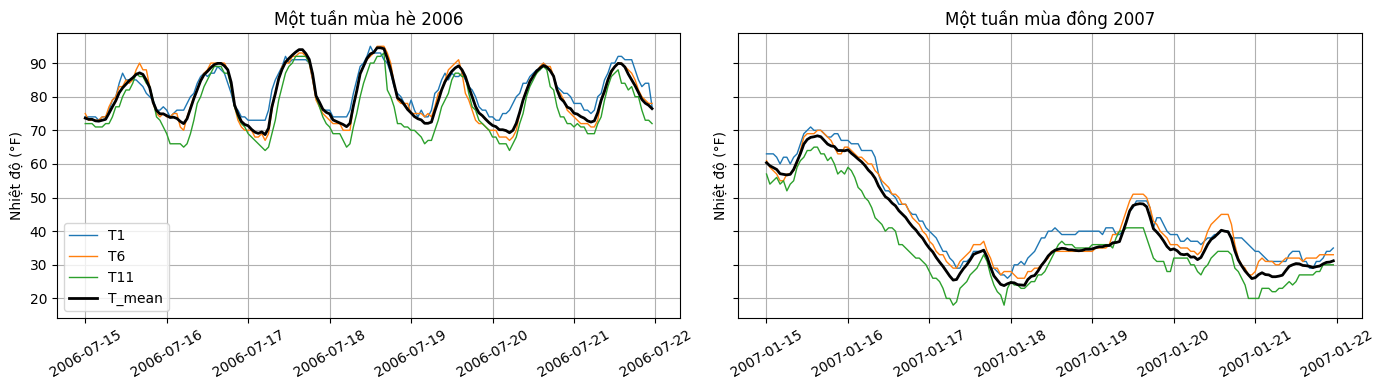

Tương quan giữa các cặp trạm: thấp nhất 0.941, cao nhất 0.998


In [7]:
# [M5] Kiểm tra trực quan: một tuần mùa hè và một tuần mùa đông của 3 trạm
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (start, end, name) in zip(axes, [("2006-07-15", "2006-07-21", "Một tuần mùa hè 2006"),
                                         ("2007-01-15", "2007-01-21", "Một tuần mùa đông 2007")]):
    part = temp.set_index("datetime").loc[start:end]
    for col in ["T1", "T6", "T11"]:
        ax.plot(part[col], label=col, linewidth=1)
    ax.plot(part["T_mean"], label="T_mean", color="black", linewidth=2)
    ax.set_title(name)
    ax.set_ylabel("Nhiệt độ (°F)")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend()
plt.tight_layout()
plt.show()

# Mức giống nhau giữa các trạm
corr = temp[[f"T{i}" for i in range(1, 12)]].corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"Tương quan giữa các cặp trạm: thấp nhất {upper.min():.3f}, cao nhất {upper.max():.3f}")

### Nhận xét

- Phần lịch sử: 11 trạm × 1 643 ngày. Ô trống **chỉ** nằm ở ngày 30/06/2008 (`h7`–`h24`), đúng phần được bổ sung bởi file solution. Không có chỗ thiếu nào khác.
- File solution ghi giờ thứ 24 của ngày 07/07/2008 là `08Jul2008:0:00:00`, xác nhận `hk` là giờ **kết thúc** lúc k:00. Quy ước nhãn đầu khoảng (`hk` → k − 1 giờ) là nhất quán.
- Sau khi ghép: mỗi trạm có đúng **39 600 giờ liên tục**, không trùng, cùng mốc thời gian với chuỗi phụ tải.
- Nhiệt độ từng trạm nằm trong khoảng 0°F đến 104°F (khoảng −18°C đến 40°C); `T_mean` từ khoảng 7,5°F đến 100°F. Đường đi trong ngày hợp lý: thấp về đêm, cao vào buổi chiều.
- Các trạm **tương quan rất cao** với nhau (từ khoảng 0,94 đến gần 1), tức thời tiết trong vùng khá đồng đều. Chọn dùng trạm nào, hay dùng trung bình, sẽ quyết định ở notebook 03 dựa trên dữ liệu.

## 2. Ngày lễ (mục 2.8)

### Lý thuyết

**Vì sao cần ngày lễ.** Vào ngày lễ, nhiều cơ quan, nhà máy nghỉ, nên phụ tải thường thấp hơn một ngày thường cùng thời tiết, gần giống một ngày Chủ nhật. Nếu không có biến này, mô hình sẽ dự báo ngày lễ như ngày thường và sai có hệ thống.

**Đặc điểm của file `Holiday_List.csv`:**
- Danh sách **ngày lễ liên bang Mỹ** 2004–2008: mỗi dòng một ngày lễ, mỗi cột một năm.
- Ngày được ghi **bằng chữ**, ví dụ `"Monday, July 5"`, nên phải tự chuyển thành ngày tháng.
- Đây là ngày **nghỉ thực tế** (*observed*), đã tính **nghỉ bù**: lễ rơi vào thứ Bảy thì nghỉ thứ Sáu trước đó, rơi vào Chủ nhật thì nghỉ thứ Hai sau đó. Ví dụ:
  - Independence Day 2004: 04/07/2004 là Chủ nhật → nghỉ **thứ Hai 05/07**.
  - New Year's Day 2005: 01/01/2005 là thứ Bảy → nghỉ **thứ Sáu 31/12/2004**. Ô này ghi thêm năm: `"Friday, December 31, 2004"`, nghĩa là ngày nghỉ **thuộc năm trước** dù nằm ở cột 2005.
- Năm 2008 chỉ có các ngày lễ đến tháng 7, vì dữ liệu kết thúc ngày 07/07/2008.

### Mục đích

- **[M1]** Chuyển chữ thành ngày tháng **đúng**, kể cả trường hợp ngày nghỉ rơi sang năm trước.
- **[M2]** **Tự kiểm tra** việc chuyển đổi: thứ ghi trong chữ phải trùng với thứ của ngày đã chuyển.
- **[M3]** Đảm bảo danh sách nằm trong khoảng thời gian của dữ liệu.

### Việc cần làm

1. Đọc file, xem cấu trúc.
2. Với mỗi ô: tách theo dấu phẩy thành `[thứ, tháng ngày]` hoặc `[thứ, tháng ngày, năm]`; nếu có năm thì dùng năm đó, không thì dùng năm của cột.
3. So thứ trong chữ với thứ của ngày đã chuyển.

In [8]:
holiday_raw = pd.read_csv(RAW_DIR / "Holiday_List.csv", index_col=0)   # cột đầu (tên ngày lễ) làm chỉ mục
holiday_raw

,2004,2005,2006,2007,2008
New Year's Day,"Thursday, January 1","Friday, December 31, 2004","Monday, January 2","Monday, January 1","Tuesday, January 1"
"Birthday of Martin Luther King, Jr.","Monday, January 19","Monday, January 17","Monday, January 16","Monday, January 15","Monday, January 21"
Washington's Birthday,"Monday, February 16","Monday, February 21","Monday, February 20","Monday, February 19","Monday, February 18"
Memorial Day,"Monday, May 31","Monday, May 30","Monday, May 29","Monday, May 28","Monday, May 26"
Independence Day,"Monday, July 5","Monday, July 4","Tuesday, July 4","Wednesday, July 4","Friday, July 4"
Labor Day,"Monday, September 6","Monday, September 5","Monday, September 4","Monday, September 3",NaN
Columbus Day,"Monday, October 11","Monday, October 10","Monday, October 9","Monday, October 8",NaN
Veterans Day,"Thursday, November 11","Friday, November 11","Friday, November 10","Monday, November 12",NaN
Thanksgiving Day,"Thursday, November 25","Thursday, November 24","Thursday, November 23","Thursday, November 22",NaN
Christmas Day,"Friday, December 24","Monday, December 26","Monday, December 25","Tuesday, December 25",NaN


In [9]:
rows = []
for holiday, by_year in holiday_raw.iterrows():          # duyệt từng ngày lễ (từng dòng)
    for year, text in by_year.items():                   # duyệt từng năm (từng cột)
        if pd.isna(text):                                # ô trống: năm 2008 chưa đến ngày lễ đó
            continue
        parts = [p.strip() for p in str(text).split(",")]
        # parts = ["Monday", "July 5"]  hoặc  ["Friday", "December 31", "2004"]
        weekday_text, month_day = parts[0], parts[1]
        real_year = parts[2] if len(parts) == 3 else year            # [M1] năm ghi riêng thì ưu tiên
        date = pd.to_datetime(f"{month_day} {real_year}", format="%B %d %Y")   # [M1] "July 5 2004" -> 2004-07-05
        rows.append({"date": date, "holiday": holiday, "column_year": int(year),
                     "weekday_text": weekday_text})

holidays = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)

# [M2] Thứ trong chữ phải trùng thứ của ngày đã chuyển
holidays["weekday_ok"] = holidays["weekday_text"] == holidays["date"].dt.day_name()
print("Số ngày lễ:", len(holidays), "| thứ khớp ở mọi dòng:", holidays["weekday_ok"].all())

# [M3] Nằm trong khoảng dữ liệu?
print("Từ", holidays["date"].min().date(), "đến", holidays["date"].max().date())

# Các trường hợp ngày nghỉ khác ngày lễ gốc hoặc khác năm của cột
holidays[holidays["date"].dt.year != holidays["column_year"]]

Số ngày lễ: 45 | thứ khớp ở mọi dòng: True
Từ 2004-01-01 đến 2008-07-04


,date,holiday,column_year,weekday_text,weekday_ok
10,2004-12-31,New Year's Day,2005,Friday,True


In [10]:
assert holidays["weekday_ok"].all()
assert holidays["date"].between(system["datetime"].min(), system["datetime"].max()).all()
assert len(holidays) == 4 * 10 + 5           # 10 ngày lễ/năm cho 2004-2007, 5 ngày cho 2008 (đến tháng 7)

holidays = holidays[["date", "holiday"]]
print(holidays["date"].dt.day_name().value_counts())

date
Monday       30
Thursday      6
Friday        5
Tuesday       3
Wednesday     1
Name: count, dtype: int64


### Nhận xét

- Có **45** ngày lễ: 10 ngày/năm cho 2004–2007 và 5 ngày cho nửa đầu 2008.
- Thứ ghi trong chữ **trùng khớp** với thứ của ngày đã chuyển ở mọi dòng: việc chuyển đổi đúng.
- Trường hợp đặc biệt duy nhất là **New Year's Day 2005**, được nghỉ vào **31/12/2004**, đã được xử lý đúng nhờ đọc năm ghi trong ô.
- Ngày lễ rơi chủ yếu vào thứ Hai (nhiều ngày lễ Mỹ được ấn định vào thứ Hai), không có ngày nào vào cuối tuần, đúng với quy tắc nghỉ bù.

## 3. Bảng dữ liệu tổng (mục 2.9)

### Lý thuyết

Mọi mô hình ở các giai đoạn sau (seasonal naive, ETS, SARIMAX, LightGBM, và các thought của ToT) đều đọc từ **một bảng chung**, mỗi dòng là một giờ, gồm:

| Nhóm cột | Cột | Vai trò |
|---|---|---|
| Mục tiêu | `load` | Phụ tải tổng hệ thống, giá trị cần dự báo |
| Cờ chất lượng | `is_imputed` | Giờ được lấp, **không dùng để chấm điểm** |
| Thời tiết | `T1`…`T11`, `T_mean` | Biến ngoại sinh |
| Lịch | `hour`, `dayofweek`, `month`, `year`, `dayofyear`, `is_weekend`, `is_holiday` | Biểu diễn chu kỳ ngày, tuần, năm, xu hướng và ngày đặc biệt |

**Vì sao cần các đặc trưng lịch** dù đã có cột `datetime`? Mô hình như LightGBM hay hồi quy không "hiểu" một mốc thời gian. Chúng cần các con số tách riêng như "giờ thứ mấy trong ngày", "thứ mấy trong tuần". Mỗi đặc trưng ứng với một loại chu kỳ:
- `hour` → chu kỳ ngày; `dayofweek`, `is_weekend` → chu kỳ tuần; `month`, `dayofyear` → chu kỳ năm; `year` → xu hướng dài hạn; `is_holiday` → ngày đặc biệt.

Quy ước: `dayofweek` = 0 là thứ Hai, 6 là Chủ nhật (mặc định của pandas). `hour` là giờ bắt đầu khoảng, từ 0 đến 23.

### Mục đích

- **[M1]** Ghép phụ tải với nhiệt độ **một-đối-một** theo giờ, không mất và không nhân đôi dòng.
- **[M2]** Tạo đặc trưng lịch từ `datetime`.
- **[M3]** Lưu bảng tổng cho các giai đoạn sau.

In [11]:
# [M1] validate="one_to_one": pandas báo lỗi ngay nếu một mốc giờ xuất hiện nhiều lần ở bảng nào đó
master = system.merge(temp, on="datetime", how="left", validate="one_to_one")
assert len(master) == len(system)
assert master["T_mean"].isna().sum() == 0               # giờ phụ tải nào cũng có nhiệt độ

# [M2] Đặc trưng lịch
dt = master["datetime"].dt
master["hour"] = dt.hour                               # 0..23
master["dayofweek"] = dt.dayofweek                     # 0 = thứ Hai, ..., 6 = Chủ nhật
master["month"] = dt.month
master["year"] = dt.year
master["dayofyear"] = dt.dayofyear
master["is_weekend"] = master["dayofweek"] >= 5
master["is_holiday"] = dt.normalize().isin(holidays["date"])   # normalize(): đưa về 00:00 để so với ngày lễ

print("Bảng tổng:", master.shape)
print("Số giờ ngày lễ:", master["is_holiday"].sum(), "= 45 ngày x 24 giờ")
assert master["is_holiday"].sum() == len(holidays) * 24
master.head()

Bảng tổng: (39600, 22)
Số giờ ngày lễ: 1080 = 45 ngày x 24 giờ


,datetime,load,is_imputed,T1,T2,T3,T4,T5,T6,T7,...,T10,T11,T_mean,hour,dayofweek,month,year,dayofyear,is_weekend,is_holiday
0,2004-01-01 00:00:00,1397668.0,False,46.0,38.0,44.0,45.0,42.0,44.0,45.0,...,42.0,36.0,42.363636,0,3,1,2004,1,False,True
1,2004-01-01 01:00:00,1351507.0,False,46.0,36.0,42.0,43.0,42.0,43.0,44.0,...,43.0,32.0,41.272727,1,3,1,2004,1,False,True
2,2004-01-01 02:00:00,1315742.0,False,45.0,35.0,40.0,41.0,40.0,42.0,41.0,...,43.0,31.0,39.636364,2,3,1,2004,1,False,True
3,2004-01-01 03:00:00,1308023.0,False,41.0,30.0,36.0,37.0,39.0,38.0,40.0,...,39.0,30.0,36.272727,3,3,1,2004,1,False,True
4,2004-01-01 04:00:00,1344117.0,False,39.0,30.0,34.0,33.0,40.0,38.0,35.0,...,35.0,34.0,34.636364,4,3,1,2004,1,False,True


In [12]:
# [M3] Lưu
master.to_parquet(PROCESSED_DIR / "master_system.parquet", index=False)
print(master.dtypes)

datetime      datetime64[ns]
load                 float64
is_imputed              bool
T1                   float64
T2                   float64
T3                   float64
T4                   float64
T5                   float64
T6                   float64
T7                   float64
T8                   float64
T9                   float64
T10                  float64
T11                  float64
T_mean               float64
hour                   int32
dayofweek              int32
month                  int32
year                   int32
dayofyear              int32
is_weekend              bool
is_holiday              bool
dtype: object


### Nhận xét

- Bảng tổng có **39 600 dòng × 22 cột**, mỗi dòng một giờ từ 01/01/2004 00:00 đến 07/07/2008 23:00.
- Ghép một-đối-một thành công: không mất dòng, giờ nào cũng có nhiệt độ.
- Có **1 080 giờ** ngày lễ = 45 ngày × 24 giờ.

## 4. Đóng gói vào `src/data.py` (mục 2.12)

### Lý thuyết

Notebook phù hợp để **khám phá và giải thích** từng bước, nhưng không phù hợp để **dùng lại**. Nếu notebook của giai đoạn 3, 4, 5 đều chép lại đoạn code xử lý dữ liệu, chỉ cần sửa một chỗ (ví dụ cách lấp giờ thiếu) là các bản chép sẽ lệch nhau mà không ai biết.

Cách làm chuẩn: gom code vào một **module Python** (`src/data.py`), là **nguồn duy nhất** cho việc xử lý dữ liệu. Mọi notebook sau chỉ cần:

```python
from src.data import load_dataset
df = load_dataset()
```

Hàm `load_dataset()` xây bảng tổng từ dữ liệu thô ở lần chạy đầu, lưu ra `master_system.parquet`, các lần sau chỉ đọc file đó. Tham số `rebuild=True` bắt buộc xây lại (dùng khi sửa code xử lý).

Để Python tìm thấy thư mục `src` khi chạy từ `notebooks/`, ta thêm thư mục gốc của repo (`..`) vào `sys.path`. Thư mục `src` cần một file `__init__.py` (có thể rỗng) để được coi là một package.

### Mục đích

- **[M1]** Chứng minh module cho kết quả **giống hệt** quy trình từng bước trong notebook 01 và 02.

### Việc cần làm

Gọi `load_dataset(rebuild=True)` rồi so với bảng `master` vừa tạo, bằng `pd.testing.assert_frame_equal` (so cả giá trị, kiểu dữ liệu, tên và thứ tự cột).

In [13]:
if ".." not in sys.path:
    sys.path.insert(0, "..")          # thêm thư mục gốc repo để import được src

from src.data import load_dataset

# [M1] Xây lại từ dữ liệu thô bằng module, rồi so với kết quả từng bước của notebook
from_module = load_dataset(rebuild=True)
pd.testing.assert_frame_equal(master, from_module)
print("Module src/data.py cho kết quả GIỐNG HỆT notebook:", from_module.shape)

Module src/data.py cho kết quả GIỐNG HỆT notebook: (39600, 22)


### Nhận xét

`assert_frame_equal` không báo lỗi, tức là module và notebook cho kết quả trùng khớp đến từng giá trị, kiểu dữ liệu và thứ tự cột. Từ giai đoạn 3 trở đi chỉ cần `load_dataset()`.

**Lưu ý khi sửa `src/data.py`:** Jupyter chỉ nạp module một lần. Sau khi sửa file, cần **Restart kernel** (hoặc dùng `importlib.reload`) để notebook thấy thay đổi, rồi gọi `load_dataset(rebuild=True)` để tạo lại file parquet.

## Tổng kết notebook 02

| Mục | Kết quả |
|---|---|
| 2.7 | Nhiệt độ 11 trạm, 39 600 giờ liên tục, cùng quy ước thời gian với phụ tải; các trạm tương quan rất cao |
| 2.8 | 45 ngày lễ (ngày nghỉ thực tế), kiểm tra thứ khớp 100% |
| 2.9 | Bảng tổng 39 600 × 22: phụ tải, cờ lấp, nhiệt độ, đặc trưng lịch |
| 2.12 | `src/data.py` + `load_dataset()` tái tạo đúng bảng tổng |

**File đầu ra:** `data/processed/master_system.parquet`.

**Tiếp theo:** notebook 03 phân tích khám phá (EDA) và chốt chuỗi mục tiêu, cách dùng nhiệt độ.